# E-Commerce Sales Performance Analysis

**Goal:** find which products drive revenue, where customers drop off after their first purchase, and what to do about it.

**Data:** `data/transactions_raw.csv`, 57k+ order lines (Jan 2023 - Dec 2024).
The data is **synthetic** (generated by `src/generate_data.py`) and intentionally messy, so every number in this notebook describes this dataset, not a real retailer.

**Plan:** 1) load and inspect, 2) clean, 3) EDA, 4) SKU Pareto analysis, 5) cohort / retention analysis, 6) what drives repeat purchase, 7) recommendations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 130)
BLUE, ORANGE, GREY = "#1F6FEB", "#E8590C", "#B8BEC7"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

raw = pd.read_csv("../data/transactions_raw.csv")
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

57,263 rows x 14 columns


,line_id,order_id,customer_id,order_date,country,channel,sku,category,unit_price,quantity,discount_pct,revenue,payment_method,order_status
0,1,O119111,C013586,2023-04-04,UK,Organic,SKU0340,Electronics,93.66,1,0.00,93.66,Card,Delivered
1,2,O108064,C005717,2023-02-10,UAE,Referral,SKU0152,Sports,33.18,1,0.00,33.18,Card,Delivered
2,3,O104778,C003342,2023-03-09,Germany,Organic,SKU0043,Fashion,14.69,1,5.00,13.96,UPI,Delivered
3,4,O102245,C001587,2023-07-14,UK,Paid Search,SKU0316,Books,15.92,1,20.00,12.74,UPI,Delivered
4,5,O114069,C010032,2023-04-07,India,Organic,SKU0130,Fashion,27.19,1,0.00,27.19,Card,Delivered


## 1. Inspect the raw data

In [2]:
summary = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                        "missing_%": (raw.isna().mean() * 100).round(2), "unique": raw.nunique()})
summary

,dtype,missing,missing_%,unique
line_id,int64,0,0.00,57263
order_id,str,0,0.00,33863
customer_id,str,0,0.00,24000
order_date,str,0,0.00,965
country,str,569,0.99,5
channel,str,0,0.00,5
sku,str,0,0.00,400
category,str,687,1.20,7
unit_price,float64,0,0.00,388
quantity,int64,0,0.00,8


In [3]:
raw[["unit_price", "quantity", "discount_pct", "revenue"]].describe().T

,count,mean,std,min,25%,50%,75%,max
unit_price,"57,263.00",41.18,35.38,3.38,15.92,29.21,55.33,319.99
quantity,"57,263.00",1.88,13.06,-1.00,1.00,1.00,2.00,500.00
discount_pct,"56,118.00",7.09,7.46,0.00,0.00,5.00,15.00,20.00
revenue,"57,263.00",70.72,512.32,2.70,18.09,33.08,69.73,"31,645.00"


Problems visible so far: missing `category`, `payment_method`, `discount_pct`, `country`; negative quantities; extreme quantities (max is far above the typical 1-4); and `order_date` stored as text, possibly in mixed formats.

## 2. Clean the data
Each step logs how many rows it touched so the cleaning is auditable.

In [4]:
log = {}
df = raw.copy()
log["raw rows"] = len(df)

# 2.1 exact duplicates (ignoring the surrogate line_id)
cols = [c for c in df.columns if c != "line_id"]
n0 = len(df)
df = df.drop_duplicates(subset=cols)
log["duplicate rows removed"] = n0 - len(df)

# 2.2 mixed date formats: ISO (yyyy-mm-dd) and dd/mm/yyyy
d_iso = pd.to_datetime(df.order_date, format="%Y-%m-%d", errors="coerce")
d_dmy = pd.to_datetime(df.order_date, format="%d/%m/%Y", errors="coerce")
log["dates in dd/mm/yyyy fixed"] = int(d_iso.isna().sum())
df["order_date"] = d_iso.fillna(d_dmy)
assert df.order_date.notna().all(), "unparseable dates remain"

# 2.3 invalid quantities (<= 0) and bulk-entry outliers (> 10; real orders are 1-4)
n0 = len(df)
df = df[df.quantity > 0]
log["invalid quantity (<=0) removed"] = n0 - len(df)
n0 = len(df)
df = df[df.quantity <= 10]
log["quantity outliers (>10) removed"] = n0 - len(df)

# 2.4 missing category -> the SKU's known category
sku_cat = df.dropna(subset=["category"]).groupby("sku").category.agg(lambda s: s.mode().iat[0])
log["missing category filled from SKU"] = int(df.category.isna().sum())
df["category"] = df.category.fillna(df.sku.map(sku_cat))

# 2.5 missing discount -> implied by revenue = price x qty x (1 - discount), snapped to 5% steps
implied = ((1 - df.revenue / (df.unit_price * df.quantity)) * 100 / 5).round() * 5
log["missing discount inferred from revenue"] = int(df.discount_pct.isna().sum())
df["discount_pct"] = df.discount_pct.fillna(implied.clip(lower=0))

# 2.6 missing country -> the customer's most common country, else 'Unknown'
cust_country = df.dropna(subset=["country"]).groupby("customer_id").country.agg(lambda s: s.mode().iat[0])
log["missing country filled from customer"] = int(df.country.isna().sum())
df["country"] = df.country.fillna(df.customer_id.map(cust_country)).fillna("Unknown")

# 2.7 missing payment method -> explicit 'Unknown' (cannot be inferred)
log["missing payment method -> Unknown"] = int(df.payment_method.isna().sum())
df["payment_method"] = df.payment_method.fillna("Unknown")

log["clean rows"] = len(df)
assert df[["category", "discount_pct", "country", "payment_method"]].notna().all().all()
pd.Series(log, name="rows").to_frame()

,rows
raw rows,57263
duplicate rows removed,684
dates in dd/mm/yyyy fixed,339
invalid quantity (<=0) removed,452
quantity outliers (>10) removed,113
missing category filled from SKU,672
missing discount inferred from revenue,1122
missing country filled from customer,561
missing payment method -> Unknown,842
clean rows,56014


**Business rule:** revenue is counted only on `Delivered` lines. Returned and cancelled lines are reported separately but excluded from revenue and customer analysis.

In [5]:
status = df.order_status.value_counts().to_frame("lines")
status["share_%"] = (status.lines / status.lines.sum() * 100).round(1)
print(status)
sales = df[df.order_status == "Delivered"].copy()
sales["month"] = sales.order_date.dt.to_period("M").dt.to_timestamp()
print(f"\nDelivered lines used for analysis: {len(sales):,}")

              lines  share_%
order_status                
Delivered     50417    90.00
Returned       3386     6.00
Cancelled      2211     3.90

Delivered lines used for analysis: 50,417


## 3. Exploratory analysis

In [6]:
n_orders = sales.order_id.nunique()
n_cust = sales.customer_id.nunique()
kpis = {
    "Revenue": f"{sales.revenue.sum():,.0f}",
    "Orders": f"{n_orders:,}",
    "Customers": f"{n_cust:,}",
    "Average order value": f"{sales.revenue.sum() / n_orders:,.2f}",
    "Orders per customer": f"{n_orders / n_cust:.2f}",
    "Return rate (lines)": f"{(df.order_status == 'Returned').mean():.1%}",
    "Cancellation rate (lines)": f"{(df.order_status == 'Cancelled').mean():.1%}",
}
pd.Series(kpis, name="value").to_frame()

,value
Revenue,"2,717,485"
Orders,"31,957"
Customers,"22,948"
Average order value,85.04
Orders per customer,1.39
Return rate (lines),6.0%
Cancellation rate (lines),3.9%


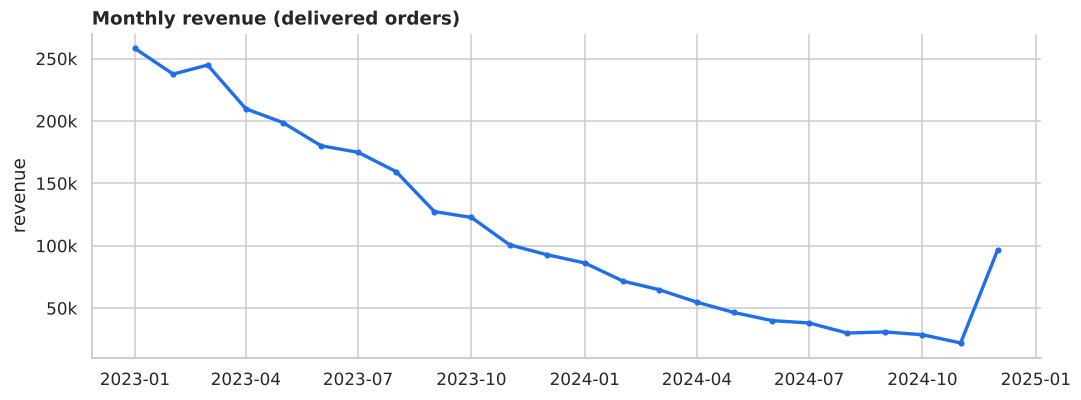

In [7]:
monthly = sales.groupby("month").agg(revenue=("revenue", "sum"), orders=("order_id", "nunique"),
                                      customers=("customer_id", "nunique"))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(monthly.index, monthly.revenue, color=BLUE, lw=2.2, marker="o", ms=3)
ax.set_title("Monthly revenue (delivered orders)", fontweight="bold", loc="left")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
ax.set_xlabel(""); ax.set_ylabel("revenue")
plt.tight_layout(); plt.savefig("../images/01_monthly_revenue.png", dpi=150); plt.show()

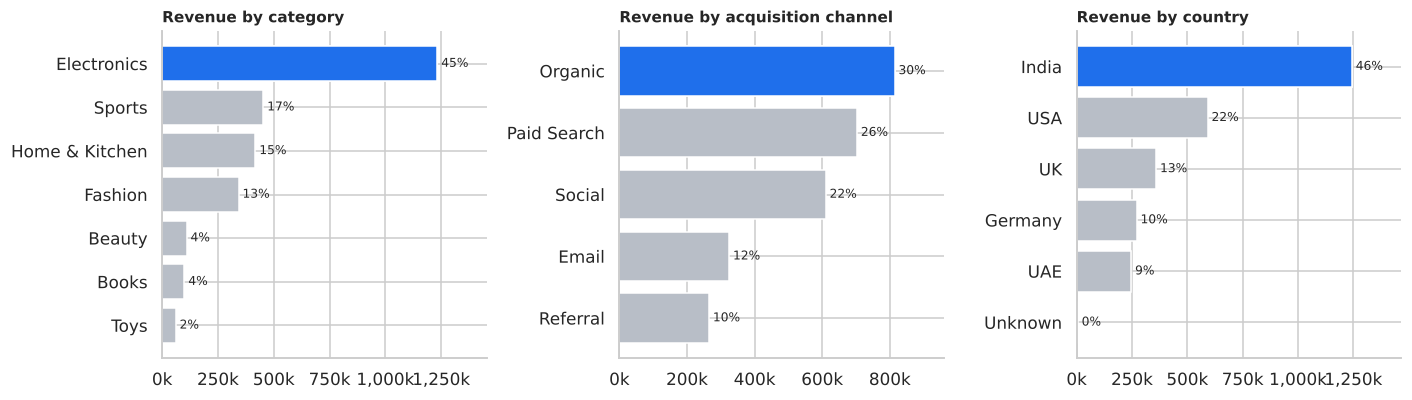

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, title in zip(axes, ["category", "channel", "country"],
                          ["Revenue by category", "Revenue by acquisition channel", "Revenue by country"]):
    s = sales.groupby(col).revenue.sum().sort_values()
    ax.barh(s.index, s.values, color=GREY)
    ax.barh(s.index[-1], s.values[-1], color=BLUE)
    for i, v in enumerate(s.values):
        ax.text(v, i, f" {v/s.sum():.0%}", va="center", fontsize=8)
    ax.set_title(title, fontweight="bold", loc="left", fontsize=10)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
    ax.set_xlim(0, s.max() * 1.18)
plt.tight_layout(); plt.savefig("../images/02_revenue_breakdown.png", dpi=150); plt.show()

## 4. SKU Pareto analysis: which products drive sales?

In [9]:
sku_rev = sales.groupby("sku").revenue.sum().sort_values(ascending=False)
cum_share = sku_rev.cumsum() / sku_rev.sum()
n_sku = len(sku_rev)
n_for_60 = int((cum_share < 0.60).sum() + 1)
n_for_80 = int((cum_share < 0.80).sum() + 1)
top20_share = cum_share.iloc[int(n_sku * 0.20) - 1]
print(f"SKUs with sales: {n_sku}")
print(f"Top 20% of SKUs ({int(n_sku*0.2)}) generate {top20_share:.1%} of revenue")
print(f"{n_for_60} SKUs ({n_for_60/n_sku:.1%} of catalogue) generate 60% of revenue")
print(f"{n_for_80} SKUs ({n_for_80/n_sku:.1%} of catalogue) generate 80% of revenue")

SKUs with sales: 400
Top 20% of SKUs (80) generate 68.4% of revenue
55 SKUs (13.8% of catalogue) generate 60% of revenue
132 SKUs (33.0% of catalogue) generate 80% of revenue


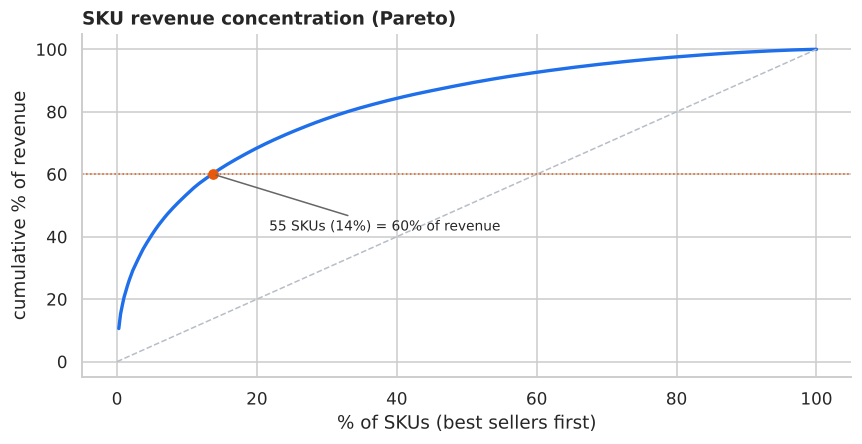

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(1, n_sku + 1) / n_sku * 100
ax.plot(x, cum_share.values * 100, color=BLUE, lw=2.2)
ax.plot([0, 100], [0, 100], color=GREY, ls="--", lw=1)
ax.axhline(60, color=ORANGE, lw=1, ls=":")
ax.scatter([n_for_60 / n_sku * 100], [60], color=ORANGE, zorder=3)
ax.annotate(f"{n_for_60} SKUs ({n_for_60/n_sku:.0%}) = 60% of revenue",
            (n_for_60 / n_sku * 100, 60), (n_for_60 / n_sku * 100 + 8, 42), fontsize=9,
            arrowprops=dict(arrowstyle="-", color="#666"))
ax.set_title("SKU revenue concentration (Pareto)", fontweight="bold", loc="left")
ax.set_xlabel("% of SKUs (best sellers first)"); ax.set_ylabel("cumulative % of revenue")
plt.tight_layout(); plt.savefig("../images/03_sku_pareto.png", dpi=150); plt.show()

In [11]:
top = (sales.groupby(["sku", "category"]).agg(revenue=("revenue", "sum"), units=("quantity", "sum"),
                                               orders=("order_id", "nunique"))
       .sort_values("revenue", ascending=False).head(10).reset_index())
top["share_of_revenue_%"] = top.revenue / sales.revenue.sum() * 100
top

,sku,category,revenue,units,orders,share_of_revenue_%
0,SKU0340,Electronics,"287,929.44",3301,2291,10.60
1,SKU0226,Electronics,"125,402.00",1066,751,4.61
2,SKU0333,Sports,"76,054.08",1177,830,2.80
3,SKU0319,Electronics,"70,219.36",605,444,2.58
4,SKU0303,Sports,"53,095.25",400,274,1.95
5,SKU0345,Electronics,"50,602.32",636,436,1.86
6,SKU0186,Electronics,"46,874.46",299,204,1.72
7,SKU0397,Sports,"42,524.14",946,659,1.56
8,SKU0216,Home & Kitchen,"40,306.53",3830,2654,1.48
9,SKU0316,Books,"32,768.82",2220,1592,1.21


In [12]:
tier = np.where(sku_rev.index.isin(sku_rev.index[:n_for_60]), "Top SKUs (60% of revenue)", "Remaining SKUs")
cat_mix = (sales.assign(tier=sales.sku.map(dict(zip(sku_rev.index, tier))))
           .groupby(["tier", "category"]).revenue.sum().unstack(0).fillna(0))
(cat_mix / cat_mix.sum()).mul(100).round(1)

tier,Remaining SKUs,Top SKUs (60% of revenue)
category,,
Beauty,10.20,0.00
Books,6.20,2.00
Electronics,16.70,64.30
Fashion,21.40,6.80
Home & Kitchen,22.60,10.60
Sports,17.30,16.30
Toys,5.60,0.00


## 5. Cohort analysis: retention after the first purchase
A customer's **cohort** is the month of their first delivered order. Retention at month *k* is the share of the cohort that ordered again *k* months later.

In [13]:
first_date = sales.groupby("customer_id").order_date.min().rename("first_date")
sales = sales.join(first_date, on="customer_id")
sales["cohort"] = sales.first_date.dt.to_period("M")
sales["order_month"] = sales.order_date.dt.to_period("M")
sales["period"] = (sales.order_month - sales.cohort).apply(lambda p: p.n)

cohort_counts = sales.groupby(["cohort", "period"]).customer_id.nunique().unstack()
retention = cohort_counts.divide(cohort_counts[0], axis=0)
print("Average retention by months since first purchase (cohorts old enough to be observed):")
obs = {}
last_month = sales.order_month.max()
for k in range(1, 7):
    ok = [c for c in retention.index if (last_month - c).n >= k]
    obs[f"month {k}"] = retention.loc[ok, k].mean()
pd.Series(obs, name="avg retention").map("{:.1%}".format).to_frame()

Average retention by months since first purchase (cohorts old enough to be observed):


,avg retention
month 1,8.8%
month 2,6.7%
month 3,5.1%
month 4,3.3%
month 5,2.7%
month 6,2.1%


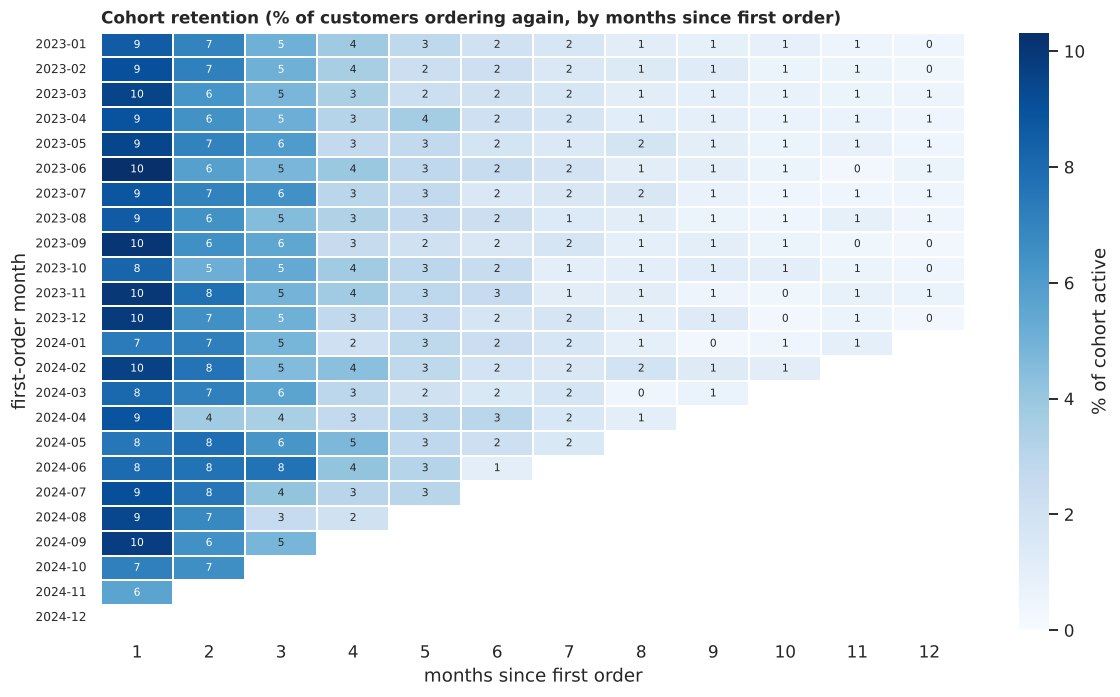

In [14]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(retention.iloc[:, 1:13].mul(100), ax=ax, cmap="Blues", annot=True, fmt=".0f",
            annot_kws={"fontsize": 7}, cbar_kws={"label": "% of cohort active"}, linewidths=.3,
            vmin=0, vmax=max(10, float(np.nanmax(retention.iloc[:, 1:13].values * 100))))
ax.grid(False)
ax.set_yticklabels([str(c) for c in retention.index], rotation=0, fontsize=8)
ax.set_title("Cohort retention (% of customers ordering again, by months since first order)",
             fontweight="bold", loc="left", fontsize=11)
ax.set_xlabel("months since first order"); ax.set_ylabel("first-order month")
plt.tight_layout(); plt.savefig("../images/04_cohort_retention.png", dpi=150); plt.show()

### Customer drop-off after the first purchase
Raw "never ordered again" is biased: recent customers have had no time to return. So I measure a **fair window**: among customers whose first order was at least 90 days before the end of the data, what share did **not** place a second order within 90 days?

In [15]:
orders = (sales.drop_duplicates("order_id")[["customer_id", "order_id", "order_date", "channel", "country"]]
          .sort_values(["customer_id", "order_date", "order_id"]))
orders["n"] = orders.groupby("customer_id").cumcount() + 1
second_date = orders[orders.n == 2].set_index("customer_id").order_date
days_to_second = (second_date - first_date).dt.days.reindex(first_date.index)

cutoff = sales.order_date.max() - pd.Timedelta(days=90)
mature = first_date.index[first_date <= cutoff]
repeat90 = (days_to_second.reindex(mature) <= 90)
drop_off = 1 - repeat90.mean()

one_and_done = (orders.groupby("customer_id").size() == 1).mean()
print(f"Customers with exactly one order (all customers, biased by recency): {one_and_done:.1%}")
print(f"Mature customers (first order >=90 days before data end): {len(mature):,}")
print(f"  placed a 2nd order within 90 days: {repeat90.mean():.1%}")
print(f"  DROP-OFF after first purchase (no 2nd order in 90 days): {drop_off:.1%}")
print(f"Median days to 2nd order (those who returned): {days_to_second.dropna().median():.0f}")

Customers with exactly one order (all customers, biased by recency): 76.4%
Mature customers (first order >=90 days before data end): 21,656
  placed a 2nd order within 90 days: 19.3%
  DROP-OFF after first purchase (no 2nd order in 90 days): 80.7%
Median days to 2nd order (those who returned): 44


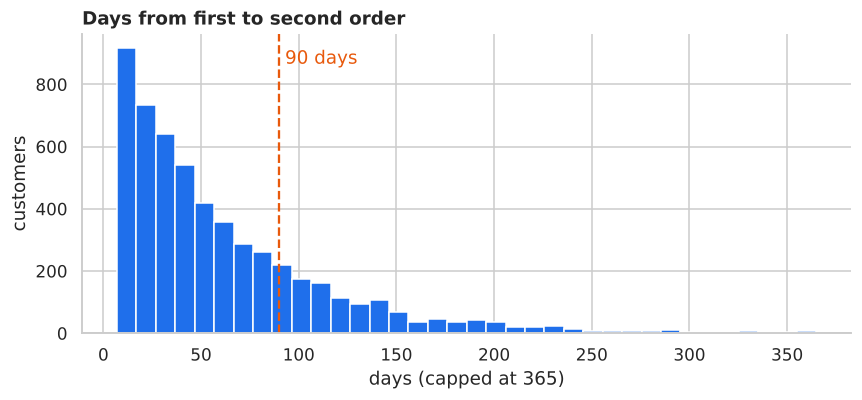

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8))
d = days_to_second.dropna()
ax.hist(d.clip(upper=365), bins=36, color=BLUE)
ax.axvline(90, color=ORANGE, ls="--"); ax.text(93, ax.get_ylim()[1] * .9, "90 days", color=ORANGE)
ax.set_title("Days from first to second order", fontweight="bold", loc="left")
ax.set_xlabel("days (capped at 365)"); ax.set_ylabel("customers")
plt.tight_layout(); plt.savefig("../images/05_days_to_second_order.png", dpi=150); plt.show()

In [17]:
rev_by_cust = sales.groupby("customer_id").revenue.sum()
n_orders_by_cust = orders.groupby("customer_id").size()
repeaters = n_orders_by_cust[n_orders_by_cust >= 2].index
print(f"Repeat customers (2+ orders): {len(repeaters)/len(n_orders_by_cust):.1%} of customers "
      f"but {rev_by_cust[repeaters].sum()/rev_by_cust.sum():.1%} of revenue")

Repeat customers (2+ orders): 23.6% of customers but 44.8% of revenue


## 6. What drives repeat purchase?
Same 90-day repeat metric, split by attributes of the first order.

In [18]:
first_orders = orders[orders.n == 1].set_index("customer_id")
fo_lines = sales.merge(first_orders[["order_id"]].reset_index(drop=True), on="order_id")
prim_cat = fo_lines.sort_values("revenue", ascending=False).drop_duplicates("order_id").set_index("customer_id")
seg = pd.DataFrame({
    "repeat90": repeat90.astype(int),
    "channel": first_orders.channel.reindex(mature),
    "country": first_orders.country.reindex(mature),
    "first_category": prim_cat.category.reindex(mature),
    "first_discounted": (prim_cat.discount_pct.reindex(mature) > 0).map({True: "Discounted", False: "Full price"}),
    "first_payment": prim_cat.payment_method.reindex(mature),
})
tables = {}
# 'Unknown' country only exists for single-order customers (nothing to infer it from), which would
# mechanically show ~0% repeat, so it is excluded from the country split.
for col in ["channel", "first_category", "first_discounted", "first_payment", "country"]:
    src = seg[seg.country != "Unknown"] if col == "country" else seg
    t = src.groupby(col).repeat90.agg(["mean", "size"]).rename(columns={"mean": "repeat_rate_90d", "size": "customers"})
    tables[col] = t.sort_values("repeat_rate_90d", ascending=False)
    print(f"\n-- by {col}")
    print(tables[col].assign(repeat_rate_90d=lambda x: (x.repeat_rate_90d * 100).round(1)).to_string())


-- by channel
             repeat_rate_90d  customers
channel                                
Paid Search            20.10       5559
Email                  19.80       2629
Social                 19.00       4816
Organic                18.90       6537
Referral               18.70       2115

-- by first_category
                repeat_rate_90d  customers
first_category                            
Beauty                    20.50       1676
Home & Kitchen            20.10       4264
Toys                      19.70        808
Fashion                   19.50       3726
Electronics               19.30       5978
Sports                    18.60       3457
Books                     17.40       1747

-- by first_discounted
                  repeat_rate_90d  customers
first_discounted                            
Discounted                  19.70      12138
Full price                  18.90       9518

-- by first_payment
               repeat_rate_90d  customers
first_payment                

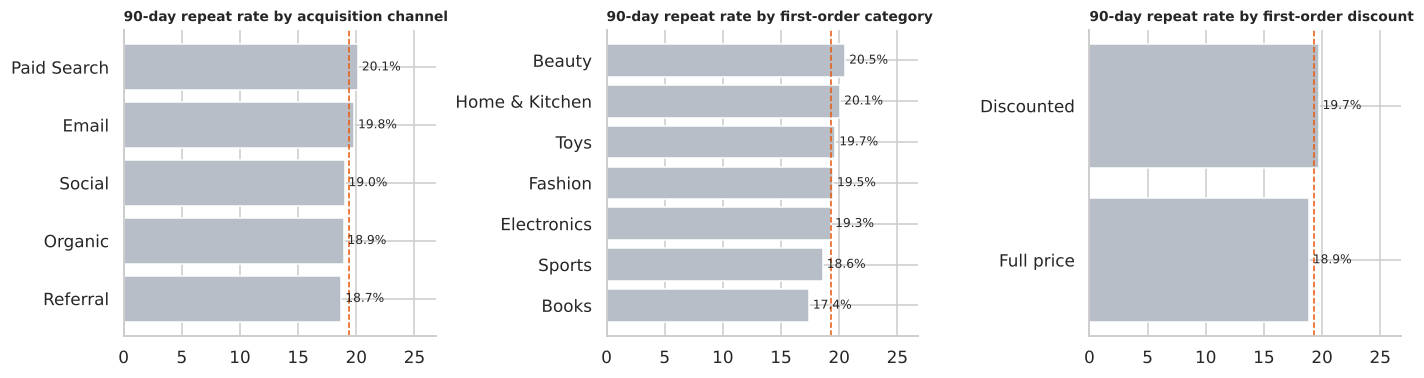

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
base = seg.repeat90.mean() * 100
for ax, col, title in zip(axes, ["channel", "first_category", "first_discounted"],
                          ["by acquisition channel", "by first-order category", "by first-order discount"]):
    t = tables[col].sort_values("repeat_rate_90d")
    ax.barh(t.index, t.repeat_rate_90d * 100, color=GREY)
    ax.axvline(base, color=ORANGE, ls="--", lw=1)
    for i, v in enumerate(t.repeat_rate_90d * 100):
        ax.text(v, i, f" {v:.1f}%", va="center", fontsize=8)
    ax.set_title("90-day repeat rate " + title, fontweight="bold", loc="left", fontsize=9)
axes[0].set_xlim(0, max(t.repeat_rate_90d.max() for t in tables.values()) * 100 * 1.3)
plt.tight_layout(); plt.savefig("../images/06_repeat_rate_segments.png", dpi=150); plt.show()

## 7. Findings and recommendations
Written from the outputs above; numbers refer to this synthetic dataset.

In [20]:
best_ch, worst_ch = tables["channel"].index[0], tables["channel"].index[-1]
best_cat, worst_cat = tables["first_category"].index[0], tables["first_category"].index[-1]
print("KEY FINDINGS")
print(f"1. {n_for_60} SKUs ({n_for_60/n_sku:.0%} of catalogue) generate 60% of revenue; top 20% of SKUs generate {top20_share:.0%}.")
print(f"2. {drop_off:.0%} of customers do not place a second order within 90 days of their first.")
print(f"3. Repeat customers are {len(repeaters)/len(n_orders_by_cust):.0%} of customers but "
      f"{rev_by_cust[repeaters].sum()/rev_by_cust.sum():.0%} of revenue.")
ch, ca = tables["channel"].repeat_rate_90d, tables["first_category"].repeat_rate_90d
print(f"4. By acquisition channel the 90-day repeat rate only ranges {ch.min():.1%} ({worst_ch}) to {ch.max():.1%} ({best_ch}): "
      f"a {100*(ch.max()-ch.min()):.1f}-point spread, so drop-off is a company-wide problem, not a channel problem.")
print(f"5. By first-order category it ranges {ca.min():.1%} ({worst_cat}) to {ca.max():.1%} ({best_cat}); "
      f"first orders with a discount repeat {tables['first_discounted'].loc['Discounted','repeat_rate_90d']:.1%} vs "
      f"{tables['first_discounted'].loc['Full price','repeat_rate_90d']:.1%} at full price.")
top_tier_cat = cat_mix["Top SKUs (60% of revenue)"] / cat_mix["Top SKUs (60% of revenue)"].sum()
print(f"6. Electronics makes up {top_tier_cat['Electronics']:.0%} of the revenue from the top-SKU tier.")
print(f"7. Half of returning customers come back within {days_to_second.dropna().median():.0f} days of their first order.")

KEY FINDINGS
1. 55 SKUs (14% of catalogue) generate 60% of revenue; top 20% of SKUs generate 68%.
2. 81% of customers do not place a second order within 90 days of their first.
3. Repeat customers are 24% of customers but 45% of revenue.
4. By acquisition channel the 90-day repeat rate only ranges 18.7% (Referral) to 20.1% (Paid Search): a 1.4-point spread, so drop-off is a company-wide problem, not a channel problem.
5. By first-order category it ranges 17.4% (Books) to 20.5% (Beauty); first orders with a discount repeat 19.7% vs 18.9% at full price.
6. Electronics makes up 64% of the revenue from the top-SKU tier.
7. Half of returning customers come back within 44 days of their first order.


## Recommendations

1. **Run a post-purchase re-engagement flow timed around day 30-45.** About four in five customers never place a second order within 90 days, and half of those who do return within about 44 days. A sequence of e.g. a day-7 usage/cross-sell email and a day-30 "restock or complementary product" offer targets the window where repeat purchases actually happen.
2. **Treat retention as a company-wide problem, not a channel problem.** Repeat rate varies by only ~1.4 points across acquisition channels, so shifting budget between channels will not fix drop-off. Invest in the post-purchase experience and measure it with an A/B test (holdout group vs. flow) on the 90-day repeat rate.
3. **Protect the SKUs that carry the business.** Roughly 14% of the catalogue produces 60% of revenue, and Electronics dominates that tier. Prioritise stock availability, pricing and reviews for these SKUs, and review the long tail for rationalisation.
4. **Use first-order category as a cross-sell lever, cautiously.** Books and Sports first-time buyers repeat least (about 17-19%) while Beauty and Home & Kitchen repeat most (about 20%). Differences are small, so test targeted next-purchase recommendations before investing heavily.
5. **Do not rely on first-order discounts to build loyalty.** Discounted first orders repeat only ~0.8 points more than full-price ones; this is correlational and small.

**Limitations.** The data is synthetic, repeat-rate differences between segments are small and observational (they do not prove causes), and "customers" means customers with at least one delivered order. With real data the same notebook can be re-run unchanged after pointing it at the actual transaction export.